# Assignment 1E.1: Bayesian linear regression (known noise)

This notebook accompanies Section 1.1 of Assignment 1E, 2026. Use NumPy and SciPy for the numerical implementation and Matplotlib for plots; do not use torch. The provided data-loading cell uses pandas to read the CSV file. Do not change the seeds. Include the code of every function you implement, together with the requested plots, tables and discussion, in your report.

**Submission.** Submit your completed notebooks and any supporting source files in two clearly labelled versions: one with comments and one without comments. Both versions must contain the same executable code and produce the same results. Remove only comments from the second version. We will use the version without comments during the oral exam, where you will explain your implementation. Include the commented code in the report appendix.

**Model.** For inputs $x_i\in\mathbb R$, use the design vector $\tilde x_i=(1,x_i)^\top$ (intercept and slope), weights $w=(w_0,w_1)^\top$, and
$$
y_i=\tilde x_i^\top w+\varepsilon_i,\qquad
\varepsilon_i\overset{\mathrm{iid}}\sim\mathcal N(0,\sigma^2),\qquad
w\sim\mathcal N(m_0,S_0),
$$
with known noise variance $\sigma^2$. As discussed in the Module 1 exercise session, Exercise 1.5, the posterior and posterior predictive distribution are
$$
p(w\mid X,y)=\mathcal N(w\mid m_N,S_N),\qquad
S_N=(S_0^{-1}+\sigma^{-2}X^\top X)^{-1},\qquad
m_N=S_N(S_0^{-1}m_0+\sigma^{-2}X^\top y),
$$
$$
p(y_\star\mid x_\star,X,y)=\mathcal N\!\left(y_\star\mid\tilde x_\star^\top m_N,
\sigma^2+\tilde x_\star^\top S_N\tilde x_\star\right).
$$
Here $X\in\mathbb R^{N\times2}$ contains the design vectors as rows. Plugging in the ML weights gives the predictive distribution $\mathcal N(\tilde x_\star^\top\hat w^{\rm ML},\sigma^2)$.

The **Provided code** section contains an implementation of data simulation and functions for the closed-form posterior, the ML estimate and the posterior predictive distribution. Use these functions without modifying them. Complete the functions marked with `NotImplementedError`; that exception is a placeholder for your implementation.

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, multivariate_normal
from scipy.special import logsumexp
from sympy.stats.sampling.sample_scipy import scipy

SEED = 2026  # Do not change the seed
rng = np.random.default_rng(SEED)

## Provided code

In [25]:
def design_matrix(x):
    # Map inputs of shape [N] to the design matrix of shape [N, 2] with a bias column.
    x = np.atleast_1d(np.asarray(x, dtype=float))
    return np.column_stack([np.ones_like(x), x])


def simulate_data(N, noise_std, w_true, rng, x_low=-1.0, x_high=1.0):
    # Draw x ~ U(x_low, x_high) and y = X w_true + eps, eps ~ N(0, noise_std^2).
    x = rng.uniform(x_low, x_high, size=N)
    X = design_matrix(x)
    y = X @ w_true + rng.normal(0.0, noise_std, size=N)
    return X, y


def infer_posterior(X, y, prior_mean, prior_cov, noise_std):
    # Closed-form posterior N(w | m_N, S_N) for Bayesian linear regression with known noise.
    noise_var = noise_std**2
    prior_precision = np.linalg.inv(prior_cov)
    post_cov = np.linalg.inv(prior_precision + X.T @ X / noise_var)
    post_mean = post_cov @ (prior_precision @ prior_mean + X.T @ y / noise_var)
    return post_mean, post_cov


def ml_estimate(X, y):
    # Least-squares / maximum-likelihood weights.
    return np.linalg.lstsq(X, y, rcond=None)[0]


def predictive_posterior(X_new, post_mean, post_cov, noise_std):
    # Marginal posterior predictive mean and variance at each row of X_new.
    pred_mean = X_new @ post_mean
    pred_var = noise_std**2 + np.einsum("ij,jk,ik->i", X_new, post_cov, X_new)
    return pred_mean, pred_var

### Parameters and data (do not change)

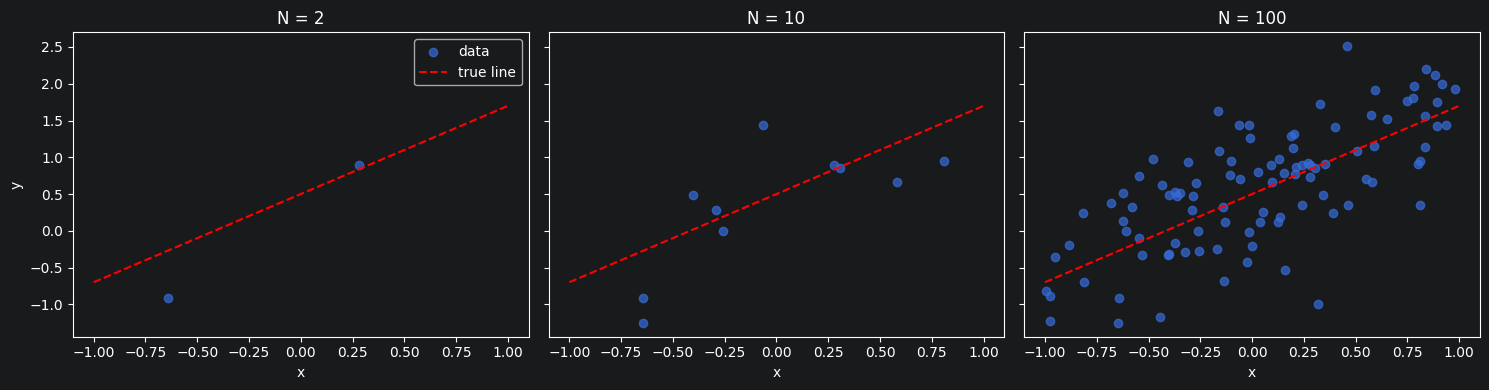

In [26]:
NOISE_STD = 0.5
PRIOR_MEAN = np.zeros(2)
PRIOR_COV = np.eye(2)
W_TRUE = np.array([0.5, 1.2])
Ns = [2, 10, 100]

# One dataset of 100 points; the N=2 and N=10 datasets are its first N points.
X_all, y_all = simulate_data(100, NOISE_STD, W_TRUE, rng)
datasets = {N: (X_all[:N], y_all[:N]) for N in Ns}

fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
x_line = np.linspace(-1, 1, 100)
for ax, N in zip(axs, Ns):
    X, y = datasets[N]
    ax.scatter(X[:, 1], y, alpha=0.7, label="data")
    ax.plot(x_line, design_matrix(x_line) @ W_TRUE, "r--", label="true line")
    ax.set_title(f"N = {N}")
    ax.set_xlabel("x")
axs[0].set_ylabel("y")
axs[0].legend()
plt.tight_layout()
plt.show()

### Question 1.1.1: Checking the posterior (2 points)

**(a)** Implement `grid_posterior`. Evaluate the unnormalised log posterior $\log p(y\mid X,w)+\log p(w)$ on the supplied grid of $(w_0,w_1)$ values, using only the likelihood and prior log-densities from `scipy.stats`, not the closed-form posterior. Normalise the density numerically on the grid. For $N=2,10,100$, overlay its contours with those of the closed-form posterior from `infer_posterior`, and report the maximum absolute difference between the two densities on the grid.

**(b)** Implement `sequential_posterior`. Process the observations one at a time, using the posterior after $n$ observations as the prior for observation $n+1$. Show that after all 100 observations the sequential and batch posteriors agree up to numerical precision by comparing their mean vectors and covariance matrices. Plot the posterior contours after $n=0,1,2,5,20,100$ observations with the true weights marked, and briefly discuss how the posterior changes.

In [27]:
def grid_posterior(w0_grid, w1_grid, X, y, prior_mean, prior_cov, noise_std):
    # Return a density array with shape (len(w0_grid), len(w1_grid)).

    noiseStdSquareMatrix = noise_std**2 * np.eye(len(X))

    prior = multivariate_normal(prior_mean, prior_cov)

    # Init log densities
    logPrior = np.zeros((len(w0_grid), len(w1_grid)))
    logLikelihood = np.zeros((len(w0_grid), len(w1_grid)))

    for i,w0 in enumerate(w0_grid):
        for j,w1 in enumerate(w1_grid):
            w = np.array([w0,w1])
            logLikelihood[i][j] = multivariate_normal(X @ w, noiseStdSquareMatrix).logpdf(y)
            logPrior[i][j] = prior.logpdf(w)
    logPost = logPrior + logLikelihood
    return logPost

For N=2, the maximum difference is 7.89759745245533e-05
For N=10, the maximum difference is 1.4210854715202004e-13
For N=100, the maximum difference is 2.7284841053187847e-12


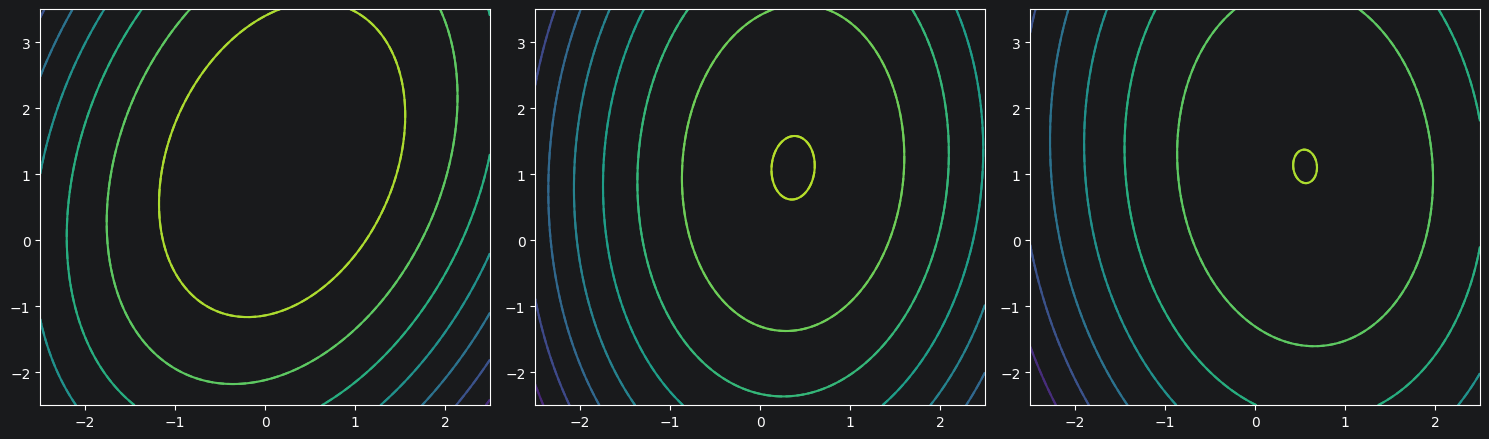

In [28]:
w0_grid = np.linspace(-2.5, 2.5, 401)
w1_grid = np.linspace(-2.5, 3.5, 401)
W0, W1 = np.meshgrid(w0_grid, w1_grid, indexing="ij")
pos = np.dstack([W0, W1])

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, N in zip(axs, Ns):
    X, y = datasets[N]

    # Compute the grid posterior and the closed-form posterior, overlay their contours
    gridPost = grid_posterior(w0_grid,w1_grid,X,y,PRIOR_MEAN,PRIOR_COV,NOISE_STD)
    dW = (w1_grid[1]-w1_grid[0])*(w0_grid[1]-w0_grid[0])
    gridPost = gridPost - logsumexp(gridPost) - np.log(dW)


    mn,sn = infer_posterior(X,y,PRIOR_MEAN,PRIOR_COV,NOISE_STD)
    closedFormPost = multivariate_normal(mn,sn).logpdf(pos)

    ax.contour(W0,W1,gridPost)
    ax.contour(W0,W1,closedFormPost,linestyles="dashed")

    #print the maximum absolute difference between the two densities.
    print(f"For N={N}, the maximum difference is {np.max(np.abs(closedFormPost - gridPost))}")
plt.tight_layout()
plt.show()



Difference for the mean is 1.1102230246251565e-15 
Difference for the cov is 2.168404344971009e-18


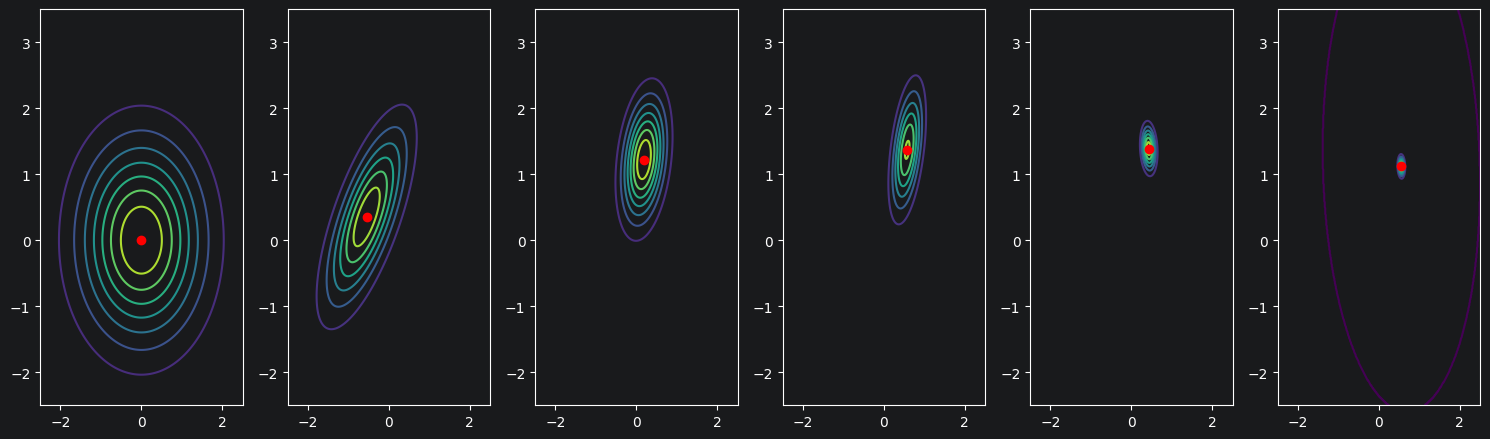

In [29]:
def sequential_posterior(X, y, prior_mean, prior_cov, noise_std):
    m = prior_mean
    s = prior_cov
    n= len(y)
    d={0: (m,s)}
    for i in range(1,n+1):
        temp = np.linalg.inv(s)
        s = np.linalg.inv(temp + np.outer(X[i-1],  X[i-1])/noise_std**2)
        m = s @ (temp @ m + (X[i-1] * y[i-1])/noise_std**2)
        d[i] = (m,s)
    return d,m,s

X, y = datasets[100]

#Seq
d,mSeq,sSeq = sequential_posterior(X,y,PRIOR_MEAN,PRIOR_COV,NOISE_STD)

#Batch
mBatch, sBatch = infer_posterior(X,y,PRIOR_MEAN,PRIOR_COV,NOISE_STD)

# Compare with the batch posterior
print(f"Difference for the mean is {np.max(np.abs(mBatch-mSeq))} ")
print(f"Difference for the cov is {np.max(np.abs(sBatch-sSeq))}")

w0_grid = np.linspace(-2.5, 2.5, 401)
w1_grid = np.linspace(-2.5, 3.5, 401)
W0, W1 = np.meshgrid(w0_grid, w1_grid, indexing="ij")
pos = np.dstack([W0, W1])

keep = [0,1,2,5,20,100]

fig, axs = plt.subplots(1, 6, figsize=(15, 4.5))
for ax, N in zip(axs, keep):
    m,s = d[N]
    prior = multivariate_normal(m,s).pdf(pos)
    ax.contour(W0,W1,prior)
    ax.plot(m[0],m[1],"ro")
plt.tight_layout()
plt.show()


In [30]:
# Compare with the batch posterior and plot the posterior after n = 0, 1, 2, 5, 20, 100 points.

At $n=0$, the ellipses are broad circles centered at $m_0$. Since no data have been observed, the posterior coincides with the prior, with mean $m_0$ and covariance $S_0$.

As $n$ increases, posterior uncertainty decreases. After a few observations, the ellipses become elongated, reflecting the fact that each observation constrains a particular direction in weight space. The posterior mean moves closer to the true weights $w^*$ (denoted by \verb|W_TRUE| in the code).

Finally, at $n=100$, the posterior is tightly concentrated around $w^*$.

## Real data: Palmer penguins (Questions 1.1.2 and 1.1.3)

The file `data/penguins.csv` contains flipper length (input $x$) and body mass (output $y$) for 342 penguins of three species, collected at Palmer Station, Antarctica (Horst, Hill & Gorman, 2020; CC0 licence). Each observation is a pair of measurements from one penguin. Both variables are standardised to zero mean and unit variance. Use the prior $\mathcal N(0,I)$.

In the provided cell below, you can find code that estimates the noise standard deviation from the residuals of a least-squares fit to the full dataset. Keep this estimate, `PEN_NOISE_STD`, fixed in the subsequent real-data experiments. Section 1.2 instead asks you to infer an unknown noise precision.

The provided code defines the **training pool** using flipper lengths at or below the 70th-percentile cutoff; the remaining observations form the **extrapolation region**. Repeated flipper lengths mean that the split need not be exactly 70%/30%.

342 penguins, sigma (standardised units) = 0.491
species in training pool: Adelie 151, Chinstrap 67, Gentoo 24
species in extrapolation region: Chinstrap 1, Gentoo 99


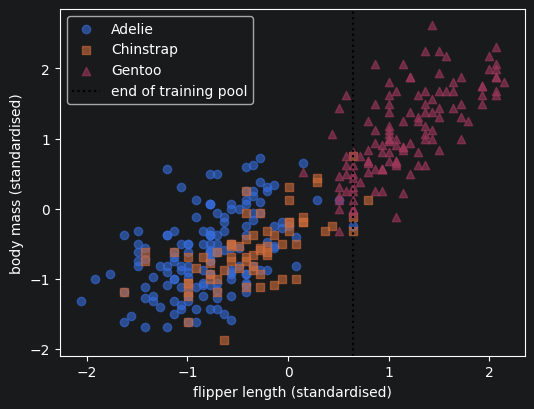

In [31]:
import pandas as pd

# Provided code (do not change)
penguins = pd.read_csv("data/penguins.csv").dropna(subset=["flipper_length_mm", "body_mass_g"]).reset_index(drop=True)
flipper = penguins["flipper_length_mm"].to_numpy(dtype=float)
mass = penguins["body_mass_g"].to_numpy(dtype=float)
species = penguins["species"].to_numpy()

x_pen = ((flipper - flipper.mean())
         / flipper.std())
y_pen = (mass - mass.mean()) / mass.std()
X_pen = design_matrix(x_pen)

w_ols_all = ml_estimate(X_pen, y_pen)
PEN_NOISE_STD = np.std(y_pen - X_pen @ w_ols_all)       # treated as known from here on

x_split = np.quantile(x_pen, 0.7)
pool_idx = np.flatnonzero(x_pen <= x_split)             # training pool (shortest 70% of flippers)
extrap_idx = np.flatnonzero(x_pen > x_split)            # extrapolation region
print(f"{len(x_pen)} penguins, sigma (standardised units) = {PEN_NOISE_STD:.3f}")
for name, idx in [("training pool", pool_idx), ("extrapolation region", extrap_idx)]:
    sp, counts = np.unique(species[idx], return_counts=True)
    print(f"species in {name}: " + ", ".join(f"{s} {c}" for s, c in zip(sp, counts)))

rng_pen = np.random.default_rng(SEED + 10)  # Do not change the seed
pen_train = {N: rng_pen.choice(pool_idx, size=N, replace=False) for N in Ns}

fig, ax = plt.subplots(figsize=(6, 4.5))
for sp, marker in zip(["Adelie", "Chinstrap", "Gentoo"], ["o", "s", "^"]):
    m = species == sp
    ax.scatter(x_pen[m], y_pen[m], marker=marker, alpha=0.6, label=sp)
ax.axvline(x_split, color="k", ls=":", label="end of training pool")
ax.set_xlabel("flipper length (standardised)"); ax.set_ylabel("body mass (standardised)")
ax.legend()
plt.show()

### Question 1.1.2: Uncertainty and extrapolation on real data (2 points)

Implement `predictive_decomposition`, which returns the aleatoric variance $\sigma^2$ and the epistemic variance $\tilde x_\star^\top S_N\tilde x_\star$ at every supplied test input. For each training set of size $N=2,10,100$, use the posterior covariance fitted to that training set and evaluate the components on the plotting grid spanning the full observed range of flipper lengths.

Produce one panel for each $N$, showing:
- all 342 observations as a scatter plot of standardised flipper length against standardised body mass, with the $N$ training observations highlighted using a distinct colour or marker;
- the posterior predictive mean and its 95% predictive interval, using the total variance $\sigma^2+\tilde x_\star^\top S_N\tilde x_\star$;
- the pointwise 95% posterior credible interval for the noise-free regression mean,
  $$\tilde x_\star^\top m_N\ \pm\ 1.96\sqrt{\tilde x_\star^\top S_N\tilde x_\star};$$
- the ML prediction and its interval $\tilde x_\star^\top\hat w^{\rm ML}\pm1.96\sigma$.

The credible interval for the regression mean excludes observation noise. Compare the widths of all three intervals within the training-pool input range and in the extrapolation region, and explain how they change with $N$. For the Bayesian and ML predictive intervals, discuss how well they include the observed body masses in the extrapolation region.

In [32]:
def predictive_decomposition(X_new, post_cov, noise_std):
    # Return aleatoric and epistemic variance arrays, each of length len(X_new).
    n= len(X_new)
    aleatoric = np.full(n,noise_std**2)
    epistemic = np.einsum("ij,jk,ik->i", X_new, post_cov, X_new)
    return aleatoric, epistemic

N = 2, Interval = Predictive interval : width for train = 3.12
N = 2, Interval = Predictive interval : width for train = 6.69
N = 2, Interval = Credible interval : width for train = 2.39
N = 2, Interval = Credible interval : width for train = 6.39
N = 2, Interval = ML interval : width for train = 1.92
N = 2, Interval = ML interval : width for train = 1.92
N = 10, Interval = Predictive interval : width for train = 2.2
N = 10, Interval = Predictive interval : width for train = 3.0
N = 10, Interval = Credible interval : width for train = 1.03
N = 10, Interval = Credible interval : width for train = 2.28
N = 10, Interval = ML interval : width for train = 1.92
N = 10, Interval = ML interval : width for train = 1.92
N = 100, Interval = Predictive interval : width for train = 1.95
N = 100, Interval = Predictive interval : width for train = 2.03
N = 100, Interval = Credible interval : width for train = 0.3
N = 100, Interval = Credible interval : width for train = 0.62
N = 100, Interval = ML in

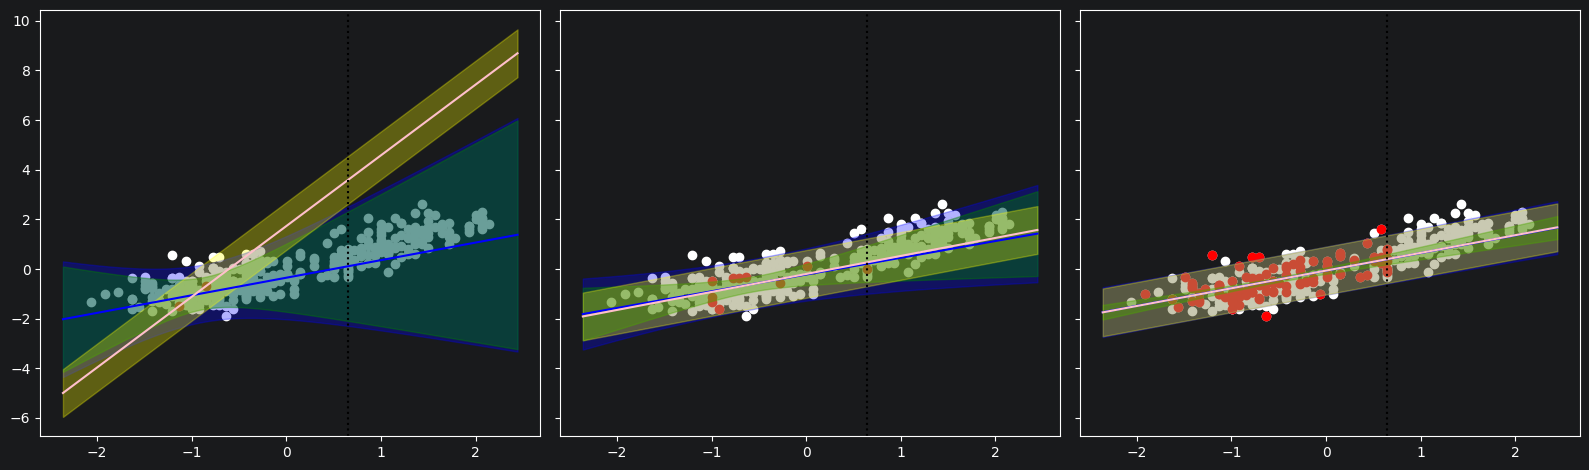

In [33]:
x_star = np.linspace(x_pen.min() - 0.3, x_pen.max() + 0.3, 300)
X_star = design_matrix(x_star)
z = norm.ppf(0.975)

idx_train = (x_star >= x_pen.min()) & (x_star <= x_split)
idx_extra = (x_star < x_pen.max()) & (x_star > x_split)

widths = {}
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, N in zip(axs, Ns):
    idx = pen_train[N]
    X, y = X_pen[idx], y_pen[idx]
    m,s = infer_posterior(X, y,PRIOR_MEAN,PRIOR_COV, PEN_NOISE_STD)
    aleatoric, epistemic = predictive_decomposition(X_star, s,PEN_NOISE_STD)

    #Scatter of all observations
    ax.scatter(x_pen, y_pen, c="white", label="Penguins")
    ax.scatter(x_pen[idx],y_pen[idx],c="red",label=f"Training for N = {N}")

    #Posterior predictive mean and 95% interval
    mean,var = predictive_posterior(X_star, m, s, PEN_NOISE_STD)
    err = z*np.sqrt(var)
    interval_pred = [mean - err, mean + err]

    ax.plot(x_star, mean,c="blue",label="Mean")
    ax.fill_between(x_star, interval_pred[0], interval_pred[1],color="blue",alpha=0.3,label="95% interval predictive")

    #95% posterior credible interval
    err = z*np.sqrt(epistemic)
    interval_cred = [mean - err, mean + err]
    ax.fill_between(x_star, interval_cred[0], interval_cred[1],color="green",alpha=0.4,label="95% interval credible")

    #ML prediction
    w_ml = ml_estimate(X,y)
    mean_ml,_ = predictive_posterior(X_star, w_ml, s, PEN_NOISE_STD)
    err = z*PEN_NOISE_STD
    interval_ml = [mean_ml - err, mean_ml + err]
    ax.plot(x_star,mean_ml,c="pink",label="Mean ML")
    ax.fill_between(x_star,interval_ml[0],interval_ml[1],color="yellow",alpha=0.3,label="95% interval ML")

    widths[N] = [interval_pred[1] - interval_pred[0], interval_cred[1] - interval_cred[0], interval_ml[1] - interval_ml[0]]
    interval_name = ["Predictive interval", "Credible interval", "ML interval"]
    for i,name in enumerate(interval_name):
        print(f"N = {N}, Interval = {name} : width for train = {np.round(widths[N][i][idx_train].mean(),2)}")
        print(f"N = {N}, Interval = {name} : width for train = {np.round(widths[N][i][idx_extra].mean(),2)}")

    ax.axvline(x_split, color="k", ls=":", label="end of training pool")
plt.tight_layout()
plt.show()

The maximum likelihood (ML) interval has a constant width: it depends neither on $x$ nor on $N$ , since $\sigma$ is constant. In contrast, the two Bayesian intervals vary depending on $x$. In areas well covered by the training data, they are narrower, and they widen as one moves away from them. The uncertainty regarding the
slope is particularly heightened during extrapolation: an identical slope error has a greater impact far from the training values.

As the training data provide more information, the uncertainty in the weights decreases :The credible interval becomes narrower, the Bayesian predictive interval narrows, while accounting for noise, the Bayesian predictive width adjusts to approach the ML width and the ML width remains unchanged.

The credible interval does not account for noise: it illustrates the uncertainty in the regression mean and should not be considered an interval intended to
encompass 95% of the individual values. Since training sets of different sizes are sampled separately, the widths do not necessarily decrease strictly at every point
for these particular realizations.With a limited amount of data, the Bayesian predictive interval better encompass the observed values during extrapolation
thanks to its additional width. The ML may often fail to include a large number of points because its line is uncertain, even though its interval does not widen to reflect this uncertainty.

As N increases, the Bayesian interval narrows, but poor extrapolation of the line may still occur. The training set consists mainly of Adelie and Chinstrap
penguins, while the extrapolation area is almost entirely populated by Gentoo penguins. The model does not account for species. A more precise estimate of
the weights therefore does not guarantee a good fit in this region. The two predictive intervals fail to capture the observed values, even with a larger amount
of data.

In conclusion, a wider Bayesian predictive interval does not guarantee that it will include a greater number of points for each training set: the Bayesian and
ML mean lines may also differ.

 ### Question 1.1.3: Calibration of predictive intervals on real data (3 points)

A 95% predictive interval is calibrated if it contains a new observation 95% of the time. Implement `coverage_real_data`. In each of $M$ repetitions:
1. draw $N$ training observations without replacement from `train_pool`;
2. draw one test observation from `test_pool`, excluding observations used for training;
3. record whether its body mass lies within the Bayesian 95% posterior predictive interval and within the ML interval $\tilde x_\star^\top\hat w^{\rm ML}\pm1.96\sigma$.

Use the prior $\mathcal N(0,I)$ for the Bayesian calculation and the fixed noise standard deviation `PEN_NOISE_STD` for both methods. Return the two empirical coverage fractions: the number of repetitions in which the interval contains the test observation, divided by $M$.

Run $M=3000$ repetitions for $N=2,10,100$ and two sampling designs:
- **random:** draw training and test observations from the full dataset;
- **extrapolation:** draw training observations from the training pool and test observations from the extrapolation region.

Convert the fractions to percentages when reporting your results. Use table columns **sampling design**, **N**, **Bayesian coverage (%)**, and **ML coverage (%)**. Explain when the Bayesian interval is approximately calibrated, when and why the ML interval fails, and why Bayesian coverage in the extrapolation design gets worse as $N$ increases.

In [34]:
def coverage_real_data(x, y, N, M, train_pool, test_pool, prior_mean, prior_cov, noise_std, rng):
    # Return the Bayesian and ML empirical coverage fractions.
    z = norm.ppf(0.975)
    ind_bayes = 0
    ind_ml = 0
    for _ in range(M):
        t_train = rng.choice(train_pool, size=N, replace=False)
        t_test = rng.choice(np.setdiff1d(test_pool,t_train), replace=False)
        X_train = design_matrix(x[t_train])
        y_train = y[t_train]
        X_test = design_matrix(x[t_test])
        y_test = y[t_test]

        #Bayesian
        m,s = infer_posterior(X_train, y_train, prior_mean, prior_cov, noise_std)
        mean, var = predictive_posterior(X_test,m,s,noise_std)
        if np.sum(np.abs(y_test- mean)) <= z*np.sqrt(var):
            ind_bayes += 1

        #ML
        wl = ml_estimate(X_train,y_train)
        mean_ml,_ = predictive_posterior(X_test,wl,s,noise_std)
        if np.sum(np.abs(y_test-mean_ml)) <= z*noise_std :
            ind_ml += 1
    return ind_bayes/M, ind_ml/M

In [35]:
M_real = 3000
rng_cov = np.random.default_rng(SEED + 1)  # Do not change the seed
all_idx = np.arange(len(x_pen))
designs = {"random": (all_idx, all_idx), "extrapolation": (pool_idx, extrap_idx)}
designs = {"random": (all_idx, all_idx), "extrapolation": (pool_idx, extrap_idx)}
# Run both designs for N in {2, 10, 100} and print a table.
for i in designs.keys():
    for N in Ns:
        prop_bayes, prop_ml = coverage_real_data(x_pen,y_pen,N,M_real,designs[i][0],designs[i][1],PRIOR_MEAN,PRIOR_COV,PEN_NOISE_STD,rng)
        print(f"Designs = {i}, N = {N} : Prop bayes : {np.round(prop_bayes*100,1)}%, Prop ML {np.round(prop_ml*100,1)}%")


Designs = random, N = 2 : Prop bayes : 96.6%, Prop ML 64.1%
Designs = random, N = 10 : Prop bayes : 95.3%, Prop ML 91.9%
Designs = random, N = 100 : Prop bayes : 94.6%, Prop ML 94.5%
Designs = extrapolation, N = 2 : Prop bayes : 96.5%, Prop ML 34.7%
Designs = extrapolation, N = 10 : Prop bayes : 87.2%, Prop ML 69.6%
Designs = extrapolation, N = 100 : Prop bayes : 83.7%, Prop ML 81.2%


When are Bayesian intervals approximately calibrated? In the random design, the empirical coverage of the Bayesian predictive intervals is close to $95 \%$ for $N=2$, $N=10$ and $N=100$. We can describe these intervals as approximately calibrated. In the extrapolation design, coverage is also close to $95\%$ for small $N$, but decreases as $N$ increases. Thus, Bayesian calibration deteriorates only in the extrapolation setting.

Why do ML intervals fail? The ML predicitve intervals account for observation noise but not for uncertainty in the estimate weights. For small $N$, their empirical coverage is low. As $N$ increases, coverage improves, but a gap to the Bayesian intervals remains.

Why does Bayesian coverage in the extrapolation design worsen as $N$ increases ? The model uses only flipper length to predict body mass, without accounting for species. Consequently, a straight line fitted primarily to observations from the first two species may not accurately predict body mass in the region occupied by Gentoo.

As $N$ increases, the weights are estimated more precisely, and the parameter uncertainty term $\tilde{x}^T_*S_N\tilde{x}_*$ decreases, which lead to narrower predictive intervals. For small $N$, wide intervals can mask poor extrapolation. For large $N$, the model becomes more confident without necessarily becoming more accurate in the extrapolation region, which explains the decline.

### Question 1.1.4: When the prior is wrong (3 points)

Return to simulated data, where the true weights are known. Implement `coverage_experiment`. In each of $M$ repetitions:
1. draw true weights $w\sim\mathcal N(w_{\rm mean},w_{\rm cov})$;
2. simulate $N$ training observations with $x\sim U(-1,1)$ and $\sigma=0.5$;
3. draw one new observation $y_\star=\tilde x_\star^\top w+\varepsilon_\star$ at the fixed test input $x_\star$;
4. record whether it lies within the Bayesian 95% predictive interval, using the supplied prior, and within the ML interval.

Return the two empirical coverage fractions, as in Question 1.1.3. Set $M=5000$, $x_\star=3$, and draw the true weights from $\mathcal N((2,2)^\top,I)$. Fit the Bayesian model with prior $\mathcal N(0,s_0^2I)$ for $s_0^2=0.1,1,10$ and $N=2,10,100$. Report the empirical coverages as percentages in a table, together with the ML coverage, which does not depend on the prior.

Discuss how prior confidence and the mismatch in the prior mean interact with $N$. When is the Bayesian predictive interval worse calibrated than the ML interval, and why? Why does the prior's influence disappear as $N$ increases, while the model misspecification in Question 1.1.3 remains?

*Optional, ungraded:* for one dataset with $N=10$ and $w=(2,2)^\top$, plot
$$\log p(y\mid X,s_0^2)=\log\mathcal N(y\mid Xm_0,\sigma^2I+s_0^2XX^\top)$$
as a function of $s_0^2$. Which value maximises it? This is the log model evidence for the regression problem. In Section 1.2, the ELBO provides a lower bound on the analogous log evidence for the Normal-Gamma model.

In [36]:
def coverage_experiment(N, x_star, M, prior_mean, prior_cov, noise_std, rng, w_mean, w_cov):
    z = norm.ppf(0.975)
    X_star = design_matrix(x_star)
    ind_bayes = 0
    ind_ml = 0

    for j in range(0,M):
        w =rng.multivariate_normal(w_mean, w_cov)
        X,y = simulate_data(N, noise_std, w, rng, x_low=-1.0, x_high=1.0)
        y_star = (X_star @ w) + rng.normal(0.0, noise_std)

        #Bayes
        m,s = infer_posterior(X, y, prior_mean, prior_cov, noise_std)
        mean, var = predictive_posterior(X_star,m,s,noise_std)
        if np.sum(np.abs(y_star-mean))<= z*np.sqrt(var):
            ind_bayes += 1

        #ML
        wl = ml_estimate(X,y)
        mean_ml, _ = predictive_posterior(X_star,wl,s,noise_std)
        if np.sum(np.abs(y_star-mean_ml)) <= z*noise_std:
            ind_ml += 1

    return ind_bayes/M, ind_ml/M


In [37]:
M = 5000
TRUE_W_MEAN = np.array([2.0, 2.0])
TRUE_W_COV = np.eye(2)
s0_sq_values = [0.1, 1.0, 10.0]
rng_mis = np.random.default_rng(SEED + 2)  # Do not change the seed
x_star = 3
# Run the experiment and print a table with one row per s0^2 (Bayes) and one row for ML.
for s0_sq in s0_sq_values:
    for N in Ns:
        prop_bayes, prop_ml = coverage_experiment(N,x_star,M,PRIOR_MEAN, s0_sq * np.eye(2),0.5,rng_mis,TRUE_W_MEAN,TRUE_W_COV)
        print(f"s0 = {s0_sq}, N = {N} : Prop bayes : {np.round(prop_bayes*100,1)}%, Prop ML : {np.round(prop_ml*100,1)}%")


s0 = 0.1, N = 2 : Prop bayes : 7.1%, Prop ML : 23.3%
s0 = 0.1, N = 10 : Prop bayes : 17.2%, Prop ML : 66.0%
s0 = 0.1, N = 100 : Prop bayes : 85.4%, Prop ML : 91.5%
s0 = 1.0, N = 2 : Prop bayes : 66.5%, Prop ML : 22.4%
s0 = 1.0, N = 10 : Prop bayes : 91.4%, Prop ML : 66.2%
s0 = 1.0, N = 100 : Prop bayes : 95.2%, Prop ML : 91.8%
s0 = 10.0, N = 2 : Prop bayes : 96.4%, Prop ML : 22.6%
s0 = 10.0, N = 10 : Prop bayes : 94.3%, Prop ML : 65.2%
s0 = 10.0, N = 100 : Prop bayes : 95.0%, Prop ML : 91.7%


In which settings is the Bayesian
predictive worse calibrated than the ML predictive, and why?  The true weight vector is approximately $(2,2)$, whereas the estimated weight vector is close to $(0,0)$. When $N$ is small, the prior can dominate the inference. An overly concentrated prior centered far from the true weights can bias the predictive mean and yield predictive intervals that do not adequately account for this error.

Bayersian predictive intervals can be worse calibrated than ML predictive intervals when the bias induced by the prior is large relative to the uncertainty captured by those intervals. Good calibration depends, in particular on the choice of prior. For $s_0^2=0.1$, we observe that Bayesian coverage is lower than ML coverage. The ML estimate is not pulled toward zero, although its predictive intervals may ignore uncertainty in the estimated weights.

Why does this problem disappear
as N grows, unlike the model misspecification in Question 1.1.3?
For a fixed prior, the prior contribution remains constant, while the contribution from the data increases with $N$. The data eventually dominate, and the posterior mean approaches the ML estimate.

In this question, the model is a linear regression with Gaussian noise and known variance. The problem comes from the prior rather than the assumed form of the relationship. By constrast, in the previous question, a single straight line may not adequately describe the relationship that is unsuitable for the test data. Predictive intervals may remain narrow even though the bias persists. This illustrates a limitation of accounting only for parameter uncertainty. The key distinction is that more data can overcome a poorly chosen prior in a correctly specified model, but cannot, on their own, correct model misspecification.

In [ ]:
# Optional (not graded)
# Insert your code here